# Лабораторна робота №9
## Класифікація зображень за допомогою CNN
**Студент:** Михайло Вахнюк. **Варіант:** 5.

**Мета:** побудувати власну згорткову мережу для трьох класів Food-101,
перевірити вплив Dropout та оцінити обрану конфігурацію на незалежному test.
Модель отримує RGB-зображення, а повертає три оцінки softmax.
Налаштування обираємо лише за validation loss; test відкриваємо після вибору.

### 1. Бібліотеки та налаштування виконання

In [1]:
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
from pathlib import Path
import sys, json, time, hashlib, shutil, platform
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score, log_loss
from sklearn.dummy import DummyClassifier
from IPython.display import display, Markdown

### 2. Шляхи проєкту, seed і параметри даних

In [1]:
ROOT = Path.cwd() if Path('Lab9_Vakhniuk.ipynb').is_file() else Path.cwd() / 'Lab9'
assert ROOT.is_dir(), 'Відкрийте ноутбук із кореня репозиторію або Lab9'
FOOD_ROOT = Path(os.environ.get('FOOD_ROOT', str(ROOT / 'datasets' / 'food-101')))
DATA_ROOT = ROOT / 'data' / 'food101_lab9'
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
SEED, NUMBER = 42, 5
IMAGE_SIZE, BATCH_SIZE, MAX_EPOCHS = (128, 128), 32, 30
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

### 3. Версії Python, TensorFlow та обладнання

In [1]:
environment = {'python': sys.version, 'tensorflow': tf.__version__, 'numpy': np.__version__,
               'platform': platform.platform(), 'processor': platform.processor(),
               'devices': [str(d) for d in tf.config.list_physical_devices()],
               'seed': SEED, 'deterministic_ops': True, 'oneDNN': os.environ['TF_ENABLE_ONEDNN_OPTS']}
(RESULTS / 'environment.json').write_text(json.dumps(environment, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(environment, ensure_ascii=False, indent=2))

{
  "python": "3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]",
  "tensorflow": "2.21.0",
  "numpy": "2.5.3",
  "platform": "Windows-11-10.0.26300-SP0",
  "processor": "Intel64 Family 6 Model 151 Stepping 2, GenuineIntel",
  "devices": [
    "PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')"
  ],
  "seed": 42,
  "deterministic_ops": true,
  "oneDNN": "0"
}


### 4. Визначення трьох класів варіанта 5

### 1 Джерело та індивідуальні класи
Food-101, Bossard, Guillaumin, Van Gool, ECCV 2014.
[Офіційне джерело](https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/).
На клас припадає 750 офіційних train та 250 test-зображень.
У навчальній частині можливі шум кольору і помилки міток.
`download_food101.py` читає офіційний архів потоком та зберігає лише потрібні класи й meta;
сторонній набір «10 percent» не використовується. Повний архів не зберігається.

Для n=5 індекси у відсортованому списку — 4, 34, 64.
Індекси Food-101 відрізняються від міток нашої моделі 0, 1, 2.

In [2]:
for filename in ('classes.txt', 'train.txt', 'test.txt'):
    assert (FOOD_ROOT / 'meta' / filename).is_file(), f'Немає {filename}; спочатку запустіть download_food101.py або задайте FOOD_ROOT'
all_classes = sorted((FOOD_ROOT / 'meta/classes.txt').read_text().splitlines())
assert len(all_classes) == 101 and 1 <= NUMBER <= 41
indices = [NUMBER - 1, NUMBER + 29, NUMBER + 59]
CLASS_NAMES = [all_classes[i] for i in indices]
print('Індекси Food-101:', list(zip(indices, CLASS_NAMES)))
print('Мітки моделі:', dict(enumerate(CLASS_NAMES)))

Індекси Food-101: [(4, 'beef_tartare'), (34, 'eggs_benedict'), (64, 'miso_soup')]
Мітки моделі: {0: 'beef_tartare', 1: 'eggs_benedict', 2: 'miso_soup'}


### 5. Читання офіційних списків train і test

### 2 Відтворюваний поділ і перевірка даних
Окремо для кожного класу перемішуємо офіційні train-ідентифікатори з seed=42:
150 у validation, решту 600 у train. Всі 250 офіційних test залишаємо для фінальної оцінки.
Маніфест містить шляхи відносно відповідної частини, ідентифікатори оригіналу та SHA-256.
Перевіряємо читабельність, точні дублікати й перетини ідентифікаторів.
При невідповідності наявних каталогів виводимо різницю і зупиняємося без видалення.

In [3]:
official = {part: (FOOD_ROOT / f'meta/{part}.txt').read_text().splitlines() for part in ('train', 'test')}

### 6. Відбір validation лише з офіційного train

In [3]:
split_ids = {'train': [], 'val': [], 'test': []}
for name in CLASS_NAMES:
    train_ids = sorted(i for i in official['train'] if i.split('/')[0] == name)
    test_ids = sorted(i for i in official['test'] if i.split('/')[0] == name)
    assert len(train_ids) == 750 and len(test_ids) == 250
    shuffled = np.random.default_rng(SEED).permutation(train_ids).tolist()
    split_ids['val'].extend(shuffled[:150])
    split_ids['train'].extend(shuffled[150:])
    split_ids['test'].extend(test_ids)

### 7. Перевірка перетинів ідентифікаторів

In [3]:
for a, b in [('train','val'), ('train','test'), ('val','test')]:
    assert not set(split_ids[a]) & set(split_ids[b])

### 8. Підготовка маніфесту

In [3]:
hash_records = defaultdict(list)
manifest = {'seed': SEED, 'student_number': NUMBER, 'food101_indices': indices,
            'class_names': CLASS_NAMES, 'source': 'https://data.vision.ee.ethz.ch/cvl/food-101.tar.gz',
            'split_method': 'sorted official train IDs; per-class default_rng(42); first 150 validation',
            'splits': {}, 'sha256': {}, 'official_ids': split_ids}

### 9. Копіювання зображень і перевірка SHA-256

In [3]:
audit, count_rows = [], []
for part, ids in split_ids.items():
    expected = {i + '.jpg' for i in ids}
    folder = DATA_ROOT / part
    if folder.exists():
        actual = {f.relative_to(folder).as_posix() for f in folder.rglob('*') if f.is_file()}
        extra = sorted(actual - expected)
        missing = sorted(expected - actual)
        if extra or missing:
            print(part, 'Зайві:', extra, 'Відсутні:', missing)
        if extra:
            raise RuntimeError('Зайві файли в каталогах; дані не видалено')
    manifest['splits'][part] = sorted(expected)
    manifest['sha256'][part] = {}
    for ident in ids:
        relative = ident + '.jpg'
        source, target = FOOD_ROOT / 'images' / relative, folder / relative
        data = source.read_bytes()
        digest = hashlib.sha256(data).hexdigest()
        with Image.open(source) as im:
            im.verify()
        with Image.open(source) as im:
            im.convert('RGB').load()
            audit.append({'split':part,'path':relative,'width':im.width,'height':im.height,'mode':im.mode,'sha256':digest})
        if target.exists():
            assert hashlib.sha256(target.read_bytes()).hexdigest() == digest, relative
        else:
            target.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(source, target)
        hash_records[digest].append({'split':part,'path':relative})
        manifest['sha256'][part][relative] = digest
    for name in CLASS_NAMES:
        count_rows.append({'split':part,'class':name,'count':sum(i.startswith(name+'/') for i in ids)})

### 10. Збереження маніфесту та підсумок перевірок

In [3]:
duplicates = [v for v in hash_records.values() if len(v)>1]
cross_duplicates = [v for v in duplicates if len({r['split'] for r in v})>1]
check = {'readable_images':len(audit), 'id_overlap':0, 'duplicate_groups':duplicates,
         'cross_split_duplicate_groups':cross_duplicates, 'automatic_deletion':False}
(ROOT / 'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
(RESULTS / 'data_checks.json').write_text(json.dumps(check, ensure_ascii=False, indent=2), encoding='utf-8')
pd.DataFrame(audit).to_csv(RESULTS / 'image_audit.csv', index=False)
counts = pd.DataFrame(count_rows)
counts.to_csv(RESULTS / 'split_counts.csv', index=False)
display(counts.pivot(index='class',columns='split',values='count'))
print('Читабельних зображень:',len(audit), 'Точних груп дублікатів:',len(duplicates), 'Між частинами:',len(cross_duplicates))
assert not cross_duplicates, 'Знайдено міжвибіркові дублікати; необхідне узгодження очищення'

split,test,train,val
class,,,
beef_tartare,250,600,150
eggs_benedict,250,600,150
miso_soup,250,600,150


Читабельних зображень: 3000 Точних груп дублікатів: 0 Між частинами: 0


### 11. Функція збереження рисунків

Фото мають різні пропорції, тло та освітлення. Resize до квадрата може спотворювати форму.
Тартар має текстуру подрібненого м’яса, яйця Бенедикт — яйце й соус на основі,
а місо-суп — бульйон із додатками; це лише візуальні підказки, а не гарантовані ознаки.
Точний SHA-256 не виявляє обрізаних або перекодованих копій.
Огляд 12 прикладів не підтверджує правильність усіх міток; автоматичного очищення не робимо.

In [4]:
def save_show(fig, name):
    fig.tight_layout()
    fig.savefig(RESULTS / name, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

### 12. По чотири навчальні приклади кожного класу

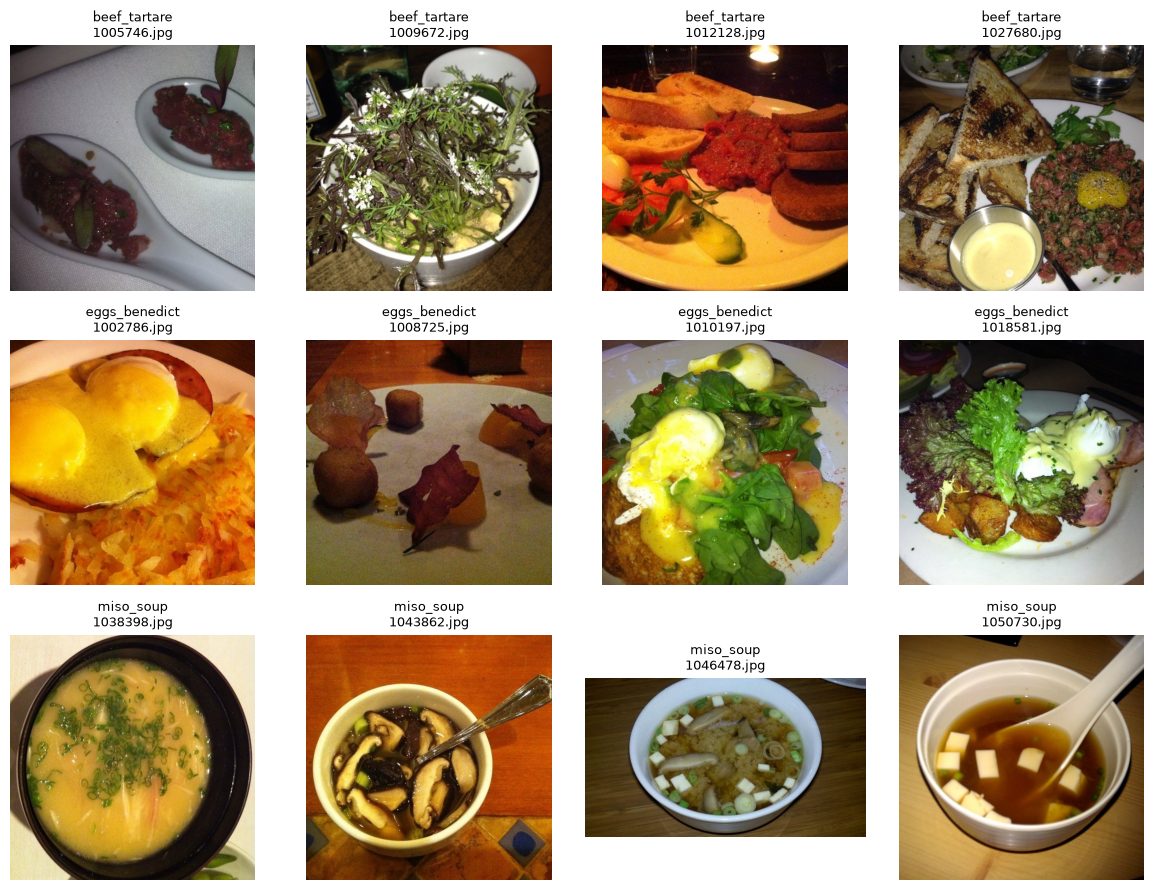

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for row, name in enumerate(CLASS_NAMES):
    candidates = [p for p in manifest['splits']['train'] if p.startswith(name+'/')]
    for col, rel in enumerate(candidates[:4]):
        with Image.open(DATA_ROOT / 'train' / rel) as im:
            axes[row,col].imshow(im.convert('RGB'))
        axes[row,col].set_title(f'{name}\n{Path(rel).name}', fontsize=9)
        axes[row,col].axis('off')
save_show(fig, 'class_examples.png')

### 13. Перевірка ручної згортки кодом

### 3 Ручна згортка
Вхід X = [[1,2,0],[0,1,3],[2,2,1]], ядро K = [[1,0],[0,−1]].
Для stride=1, padding=valid та bias=0 отримуємо:

* верхній лівий: 1·1 + 2·0 + 0·0 + 1·(−1) = **0**;
* верхній правий: 2·1 + 0·0 + 1·0 + 3·(−1) = **−1**;
* нижній лівий: 0·1 + 1·0 + 2·0 + 2·(−1) = **−2**;
* нижній правий: 1·1 + 3·0 + 2·0 + 1·(−1) = **0**.

Карта: [[0,−1],[−2,0]]. Після додавання bias=1: [[1,0],[−1,1]].
Після ReLU: **[[1,0],[0,1]]**.
Conv2D виконує взаємну кореляцію без перевертання ядра. Спільні ваги застосовуються
до кожного локального вікна, тому один фільтр шукає одну ознаку в різних позиціях.
Це сума поелементних добутків у вікні, а не звичайне множення двох матриць.

In [5]:
X = np.array([[1,2,0],[0,1,3],[2,2,1]], dtype=np.float32)
K = np.array([[1,0],[0,-1]], dtype=np.float32)
manual = np.array([[np.sum(X[r:r+2,c:c+2]*K) for c in range(2)] for r in range(2)])
actual = tf.nn.conv2d(X[None,:,:,None], K[:,:,None,None], strides=1, padding='VALID').numpy()[0,:,:,0]
np.testing.assert_array_equal(actual, [[0,-1],[-2,0]])
np.testing.assert_array_equal(actual, manual)
print('Без bias:', actual, '\nBias=1 та ReLU:', tf.nn.relu(actual+1).numpy())

Без bias: [[ 0. -1.]
 [-2.  0.]] 
Bias=1 та ReLU: [[1. 0.]
 [0. 1.]]


### 14. Завантаження батчів зображень

### 4 Батчі та архітектура
Форма входу — (B,128,128,3), міток — (B,). Кожен RGB-фільтр 3×3 має 27 ваг
та один bias; 16 фільтрів створюють 16 карт. Rescaling усередині моделі виконує
єдине ділення на 255. Int-мітки 0–2 узгоджено з Dense(3,softmax) та
SparseCategoricalCrossentropy(from_logits=False).

Форма після шару обчислюється як floor((N+2P−K)/S)+1; для same stride=1 розмір
зберігається. MaxPooling 2×2 вдвічі зменшує сторони, обираючи локальний максимум,
але може втрачати деталі. ReLU додає нелінійність.

| Етап | Форма без batch | Параметри |
|---|---|---:|
| Conv16 → Pool | 64×64×16 | (3·3·3+1)·16 = 448 |
| Conv32 → Pool | 32×32×32 | (3·3·16+1)·32 = 4640 |
| Conv64 → Pool | 16×16×64 | (3·3·32+1)·64 = 18496 |
| GAP | 64 | 0 |
| Dense softmax | 3 | (64+1)·3 = 195 |
| Разом | | **23779** |

GAP усереднює кожну просторову карту й залишає 64 числа. Flatten залишив би
16·16·64=16384 значення, а наступний Dense(3) мав би 49155 параметрів.
Cache не використовуємо, щоб не створювати великий кеш float32-зображень у RAM.

In [6]:
def load_split(part, training=False):
    ds = keras.utils.image_dataset_from_directory(
        DATA_ROOT / part, class_names=CLASS_NAMES, label_mode='int', color_mode='rgb',
        image_size=IMAGE_SIZE, interpolation='bilinear', batch_size=BATCH_SIZE,
        shuffle=training, seed=SEED)
    options = tf.data.Options()
    options.deterministic = True
    options.threading.private_threadpool_size = 4
    return ds.with_options(options).prefetch(1)

### 15. Перевірка форм і діапазону пікселів

In [6]:
train_ds = load_split('train', True)
val_ds = load_split('val')
images, labels = next(iter(train_ds))
print(images.shape, labels.shape, 'Пікселі:', float(tf.reduce_min(images)),float(tf.reduce_max(images)))
assert images.shape[1:] == (128,128,3) and labels.shape.rank == 1
assert set(labels.numpy()).issubset({0,1,2})

Found 1800 files belonging to 3 classes.


Found 450 files belonging to 3 classes.


(32, 128, 128, 3) (32,) Пікселі: 0.0 255.0


### 16. Архітектура власної CNN

In [6]:
def make_model(dropout=0.0):
    inputs = keras.Input(shape=(128,128,3), name='rgb_image')
    x = layers.Rescaling(1./255, name='rescale')(inputs)
    for i, filters in enumerate((16,32,64), 1):
        x = layers.Conv2D(filters,3,padding='same',activation='relu',name=f'conv{i}')(x)
        x = layers.MaxPooling2D(2,name=f'pool{i}')(x)
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    if dropout:
        x = layers.Dropout(dropout,seed=SEED,name='dropout')(x)
    outputs = layers.Dense(3,activation='softmax',name='class_scores')(x)
    model = keras.Model(inputs,outputs)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')])
    return model

### 17. Summary і перевірка 23 779 параметрів

In [6]:
keras.utils.set_random_seed(SEED)
preview = make_model()
preview.summary()
assert preview.count_params() == 23779

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rgb_image (InputLayer)          │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_scores (Dense)            │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,779 (92.89 KB)

 Trainable params: 23,779 (92.89 KB)

 Non-trainable params: 0 (0.00 B)

### 18. Фіксація гіпотези та правил порівняння

### 5 Контрольований експеримент
**Гіпотеза до навчання:** Dropout 0.3 після GAP може зменшити перенавчання
та validation loss, але покращення не гарантоване. Змінюємо тільки Dropout 0 → 0.3.
Спільні налаштування: Adam(0.001), batch=32, до 30 епох,
EarlyStopping за val_loss з patience=5 та відновленням найкращих ваг.
Перед кожним запуском скидаємо seed та заново створюємо train_ds.
Додатково перевіряємо ідентичність початкових навчуваних ваг.
Вибір — мінімальний validation loss; у разі рівності лишаємо базову мережу.

In [7]:
experiment_spec = {'hypothesis':'Dropout 0.3 після GAP зменшить validation loss завдяки регуляризації',
                   'changed_factor':'dropout: 0.0 -> 0.3', 'seed':SEED, 'max_epochs':MAX_EPOCHS,
                   'patience':5, 'optimizer':'Adam', 'learning_rate':0.001,
                   'selection':'minimum validation loss; tie -> base', 'test_used':False}
(RESULTS / 'experiment_plan.json').write_text(json.dumps(experiment_spec, ensure_ascii=False, indent=2),encoding='utf-8')

### 19. Навчання базової CNN і CNN з Dropout

In [7]:
models, histories, rows, initial_weights = {}, {}, [], {}
for name, dropout in [('base',0.0), ('dropout03',0.3)]:
    keras.utils.set_random_seed(SEED)
    model = make_model(dropout)
    initial_weights[name] = [v.numpy().copy() for v in model.trainable_weights]
    if name == 'dropout03':
        for a,b in zip(initial_weights['base'], initial_weights[name]):
            np.testing.assert_array_equal(a,b)
    train_ds = load_split('train', True)
    start = time.perf_counter()
    history = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS, verbose=2,
        callbacks=[keras.callbacks.CSVLogger(str(RESULTS / f'{name}_live_history.csv')),
                   keras.callbacks.EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True),
                   keras.callbacks.ModelCheckpoint(str(ROOT / f'{name}_best.keras'),monitor='val_loss',save_best_only=True)])
    seconds = time.perf_counter()-start
    hist = pd.DataFrame(history.history)
    hist.index = np.arange(1,len(hist)+1)
    hist.index.name = 'epoch'
    hist.to_csv(RESULTS / f'{name}_history.csv')
    best_epoch = int(hist['val_loss'].idxmin())
    model = keras.models.load_model(ROOT / f'{name}_best.keras')
    val = model.evaluate(val_ds,verbose=0,return_dict=True)
    rows.append({'model':name,'dropout':dropout,'parameters':model.count_params(),
                 'epochs':len(hist),'best_epoch':best_epoch,'training_seconds':seconds,
                 'val_loss':val['loss'],'val_accuracy':val['accuracy']})
    models[name], histories[name] = model, hist
    print(name, rows[-1], flush=True)

Found 1800 files belonging to 3 classes.


Epoch 1/30


C:\Users\Михайло\Data_Science_Labs\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


57/57 - 26s - 455ms/step - accuracy: 0.3783 - loss: 1.0885 - val_accuracy: 0.4711 - val_loss: 1.0517


Epoch 2/30


57/57 - 37s - 656ms/step - accuracy: 0.4794 - loss: 1.0310 - val_accuracy: 0.5356 - val_loss: 0.9540


... (100 outputs left out)

57/57 - 23s - 404ms/step - accuracy: 0.6978 - loss: 0.6947 - val_accuracy: 0.7644 - val_loss: 0.5894


Epoch 30/30


57/57 - 18s - 314ms/step - accuracy: 0.7006 - loss: 0.6711 - val_accuracy: 0.7889 - val_loss: 0.5745


dropout03 {'model': 'dropout03', 'dropout': 0.3, 'parameters': 23779, 'epochs': 30, 'best_epoch': 30, 'training_seconds': 627.8952917999995, 'val_loss': 0.5745136737823486, 'val_accuracy': 0.7888888716697693}


### 20. Таблиця validation-експериментів

In [7]:
comparison = pd.DataFrame(rows)
comparison.to_csv(RESULTS / 'validation_results.csv',index=False)
display(comparison)

,model,dropout,parameters,epochs,best_epoch,training_seconds,val_loss,val_accuracy
0,base,0.0,23779,22,17,464.766126,0.615795,0.766667
1,dropout03,0.3,23779,30,30,627.895292,0.574514,0.788889


### 21. Вибір конфігурації до test і збереження моделі

In [7]:
selected_name = 'dropout03' if rows[1]['val_loss'] < rows[0]['val_loss'] else 'base'
selected_model = models[selected_name]
decision = {'selected':selected_name, 'criterion':'minimum validation loss',
            'validation_results':rows, 'test_used':False, 'initial_trainable_weights_identical':True}
(RESULTS / 'selection_before_test.json').write_text(json.dumps(decision,indent=2),encoding='utf-8')
selected_model.save(ROOT / 'food_cnn.keras')
(ROOT / 'class_names.json').write_text(json.dumps(CLASS_NAMES,indent=2),encoding='utf-8')
print('Обрано до test:',selected_name)

Обрано до test: dropout03


### 22. Графіки loss і accuracy двох конфігурацій

Ознаку перенавчання шукаємо в зменшенні train loss одночасно зі зростанням val_loss
після найкращої епохи. EarlyStopping і checkpoint повертають модель до мінімуму val_loss.
Dropout активний під час навчання й вимкнений при оцінюванні, тому train та validation accuracy
обчислюються в різних режимах. Перевага validation accuracy сама по собі не доводить недонавчання.
Один seed і один поділ не доводять стійкості ефекту; на іншому обладнанні результат може відрізнятися.

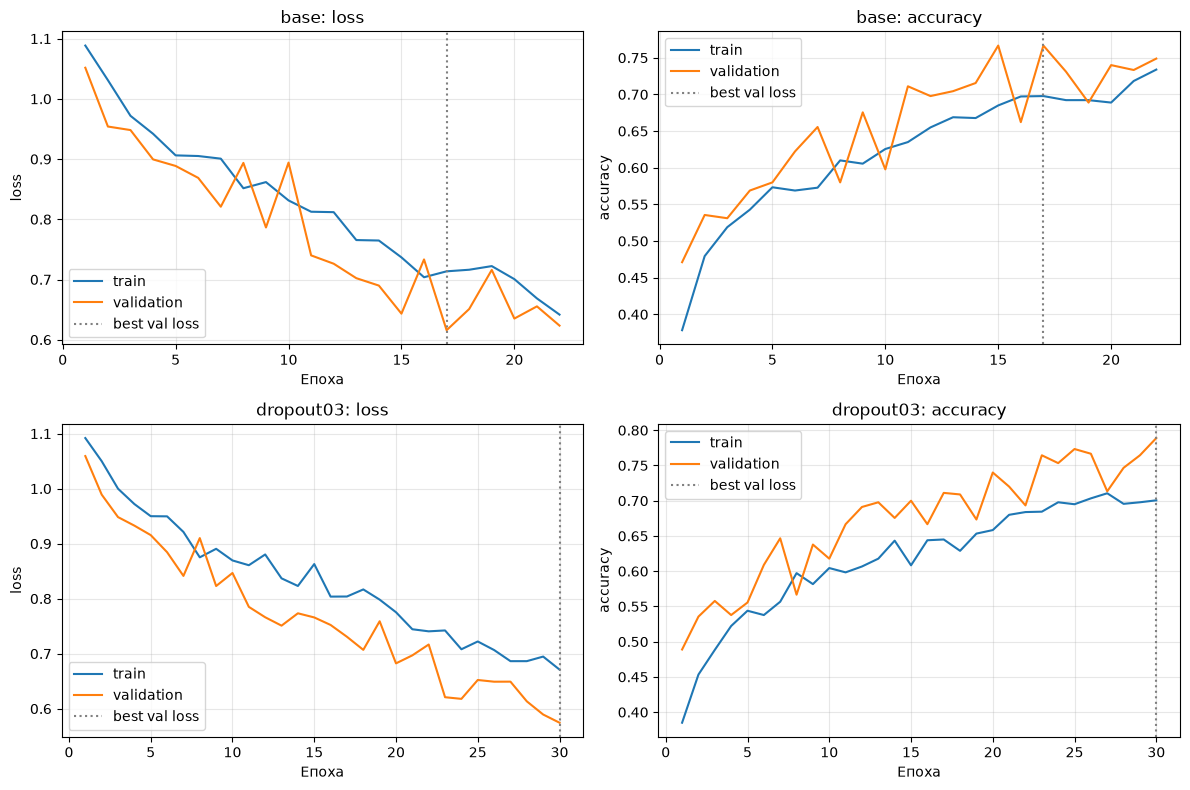

In [8]:
fig, axes = plt.subplots(2,2,figsize=(12,8))
for row, (name,hist) in enumerate(histories.items()):
    for col, metric in enumerate(['loss','accuracy']):
        ax=axes[row,col]
        ax.plot(hist.index,hist[metric],label='train')
        ax.plot(hist.index,hist['val_'+metric],label='validation')
        ax.axvline(int(hist.val_loss.idxmin()),color='gray',ls=':',label='best val loss')
        ax.set(title=f'{name}: {metric}',xlabel='Епоха',ylabel=metric)
        ax.legend(); ax.grid(alpha=.3)
save_show(fig,'training_curves.png')

### 23. Результат контрольованої зміни

In [8]:
delta = rows[1]['val_loss']-rows[0]['val_loss']
display(Markdown(f'Зміна validation loss (Dropout − base): **{delta:+.4f}**. '
                 f'Гіпотеза {"підтвердилася" if delta<0 else "не підтвердилася"} на цьому поділі. '
                 f'Обрано **{selected_name}**.'))
for name,h in histories.items():
    e=int(h.val_loss.idxmin())
    print(f'{name}: найкраща епоха {e}; train loss={h.loc[e,"loss"]:.4f}, val loss={h.loc[e,"val_loss"]:.4f}; '
          f'остання: train={h.iloc[-1]["loss"]:.4f}, val={h.iloc[-1]["val_loss"]:.4f}')

Зміна validation loss (Dropout − base): **-0.0413**. Гіпотеза підтвердилася на цьому поділі. Обрано **dropout03**.

base: найкраща епоха 17; train loss=0.7136, val loss=0.6158; остання: train=0.6417, val=0.6234
dropout03: найкраща епоха 30; train loss=0.6711, val loss=0.5745; остання: train=0.6711, val=0.5745


### 24. Фінальні test-прогнози обраної CNN

### 6 Незалежна фінальна оцінка
Конфігурацію зафіксовано у selection_before_test.json. Лише тепер завантажуємо test
без перемішування та випадкової обробки. Оцінюємо обрану CNN й Dummy most_frequent.
Іншу CNN на test не перевіряємо та гіперпараметри після test не змінюємо.

Macro-F1 усереднює F1 трьох класів з однаковою вагою; support показує кількість прикладів.
Рядки матриці — фактичні класи, стовпці — передбачені. Precision відображає частку правильних
серед прогнозів класу, recall — частку знайдених серед усіх його справжніх прикладів.
Збалансований test дає Dummy accuracy=1/3; рівномірне випадкове вгадування має очікувану accuracy=1/3.

In [9]:
test_ds = load_split('test')
test_metrics = selected_model.evaluate(test_ds,verbose=0,return_dict=True)
y_true = np.concatenate([y.numpy() for _, y in test_ds])
probabilities = selected_model.predict(test_ds,verbose=0)
y_pred = probabilities.argmax(axis=1)
test_paths = sorted(manifest['splits']['test'])
assert len(y_true) == len(test_paths) == 750
np.testing.assert_array_equal(y_true, [CLASS_NAMES.index(p.split('/')[0]) for p in test_paths])
np.testing.assert_allclose(probabilities.sum(axis=1),1,atol=1e-5)

Found 750 files belonging to 3 classes.


### 25. Precision, recall і F1 за класами

In [9]:
report = classification_report(y_true,y_pred,labels=[0,1,2],target_names=CLASS_NAMES,zero_division=0,output_dict=True)
report_df = pd.DataFrame(report).T
report_df.to_csv(RESULTS / 'classification_report.csv')
print(classification_report(y_true,y_pred,labels=[0,1,2],target_names=CLASS_NAMES,zero_division=0,digits=4))

               precision    recall  f1-score   support

 beef_tartare     0.8014    0.4520    0.5780       250
eggs_benedict     0.5695    0.8520    0.6827       250
    miso_soup     0.8809    0.8280    0.8536       250

     accuracy                         0.7107       750
    macro avg     0.7506    0.7107    0.7048       750
 weighted avg     0.7506    0.7107    0.7048       750



### 26. Порівняння з DummyClassifier

In [9]:
train_labels = [CLASS_NAMES.index(p.split('/')[0]) for p in manifest['splits']['train']]
dummy = DummyClassifier(strategy='most_frequent').fit(np.zeros((len(train_labels),1)),train_labels)
dummy_pred = dummy.predict(np.zeros((len(y_true),1)))
summary = {'selected':selected_name,'test_loss':float(test_metrics['loss']),
           'test_accuracy':float(accuracy_score(y_true,y_pred)), 'macro_f1':float(report['macro avg']['f1-score']),
           'dummy_accuracy':float(accuracy_score(y_true,dummy_pred)),
           'dummy_macro_f1':float(f1_score(y_true,dummy_pred,average='macro',zero_division=0)),
           'test_images':len(y_true),'error_count':int(np.sum(y_true!=y_pred))}
(RESULTS / 'test_metrics.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
display(pd.DataFrame([{'model':selected_name,'accuracy':summary['test_accuracy'],'macro_f1':summary['macro_f1']},
                      {'model':'Dummy most_frequent','accuracy':summary['dummy_accuracy'],'macro_f1':summary['dummy_macro_f1']}]))

,model,accuracy,macro_f1
0,dropout03,0.710667,0.704769
1,Dummy most_frequent,0.333333,0.166667


### 27. Збереження прогнозів і оцінок softmax

In [9]:
predictions = pd.DataFrame({'path':test_paths,'true_label':y_true,'predicted_label':y_pred,
                            'true_class':[CLASS_NAMES[i] for i in y_true], 'predicted_class':[CLASS_NAMES[i] for i in y_pred],
                            'max_softmax':probabilities.max(axis=1)})
for i,name in enumerate(CLASS_NAMES): predictions[f'p_{name}']=probabilities[:,i]
predictions.to_csv(RESULTS / 'test_predictions.csv',index=False)

### 28. Матриця помилок і підсумкові test-метрики

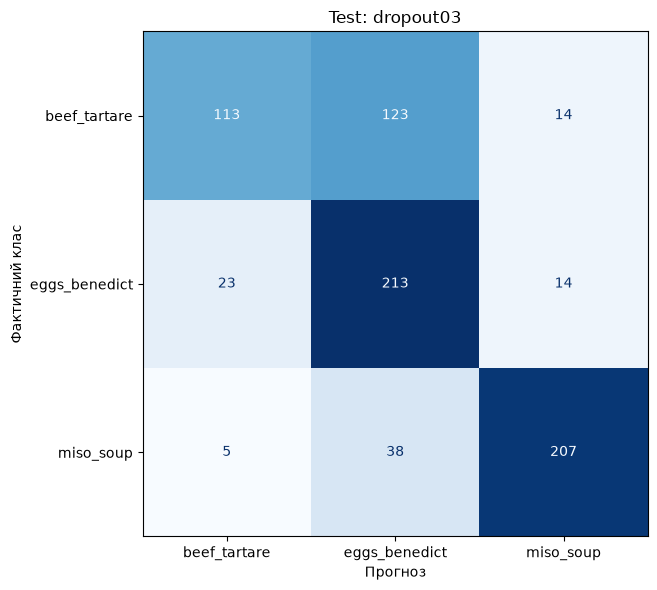

{
  "selected": "dropout03",
  "test_loss": 0.6310988068580627,
  "test_accuracy": 0.7106666666666667,
  "macro_f1": 0.704768556734834,
  "dummy_accuracy": 0.3333333333333333,
  "dummy_macro_f1": 0.16666666666666666,
  "test_images": 750,
  "error_count": 217
}


In [9]:
fig,ax=plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay.from_predictions(y_true,y_pred,labels=[0,1,2],display_labels=CLASS_NAMES,ax=ax,colorbar=False,cmap='Blues')
ax.set(title=f'Test: {selected_name}',xlabel='Прогноз',ylabel='Фактичний клас')
save_show(fig,'confusion_matrix.png')
print(json.dumps(summary,indent=2))

### 29. Функція відображення прогнозів

Впевнені помилки показують обмеження softmax: висока оцінка не гарантує правильного класу.
Під час аналізу перевіряємо схожість текстур і кольорів страв, посуд, фон, ракурс і обрізання.
Можливу помилку мітки не можна встановити лише через незгоду з моделлю.
Точні спостереження щодо отриманих прикладів наведено у висновках після візуального перегляду.

In [10]:
def show_predictions(ids,filename):
    if not len(ids):
        print('Помилок немає'); return
    fig,axes=plt.subplots(2,3,figsize=(12,8),squeeze=False)
    for ax,i in zip(axes.flat,ids):
        with Image.open(DATA_ROOT / 'test' / test_paths[i]) as im: ax.imshow(im.convert('RGB'))
        ax.set_title(f'Факт: {CLASS_NAMES[y_true[i]]}\nПрогноз: {CLASS_NAMES[y_pred[i]]}\nmax softmax={probabilities[i].max():.3f}',fontsize=10)
        ax.axis('off')
    for ax in list(axes.flat)[len(ids):]: ax.axis('off')
    save_show(fig,filename)

### 30. Шість прикладів test-прогнозів

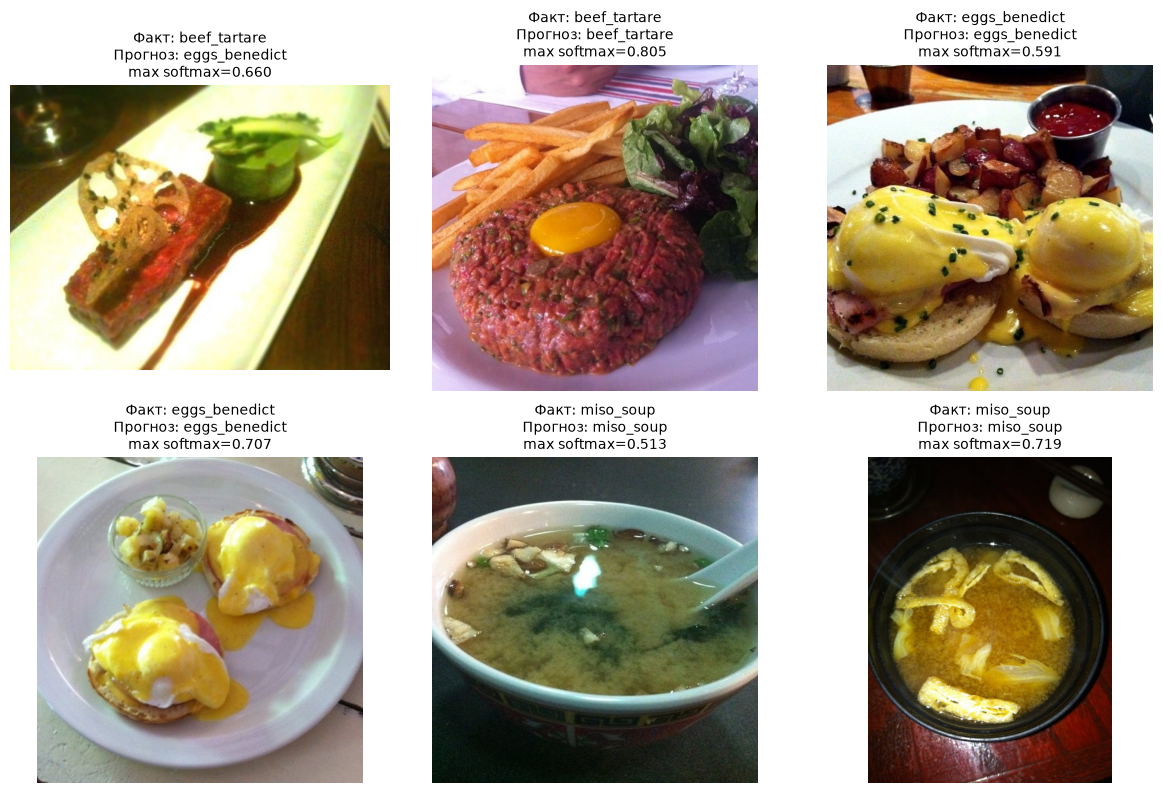

In [10]:
example_ids = np.concatenate([np.flatnonzero(y_true==c)[:2] for c in range(3)])
show_predictions(example_ids,'predictions.png')

### 31. Шість найвпевненіших помилок

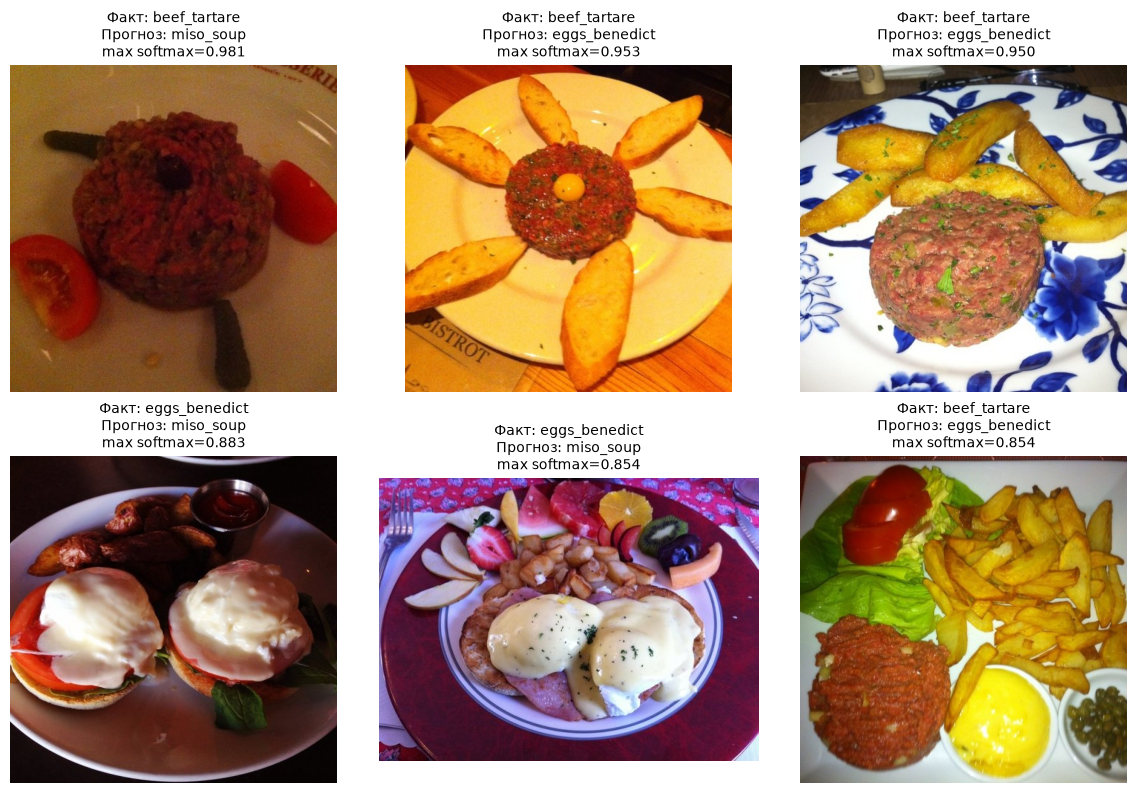

,path,true_class,predicted_class,max_softmax
103,beef_tartare/2580153.jpg,beef_tartare,miso_soup,0.980596
106,beef_tartare/2625114.jpg,beef_tartare,eggs_benedict,0.953151
228,beef_tartare/700095.jpg,beef_tartare,eggs_benedict,0.949742
274,eggs_benedict/1412040.jpg,eggs_benedict,miso_soup,0.882746
400,eggs_benedict/313588.jpg,eggs_benedict,miso_soup,0.854129
28,beef_tartare/1432088.jpg,beef_tartare,eggs_benedict,0.853960


In [10]:
errors = np.flatnonzero(y_true!=y_pred)
error_ids = errors[np.argsort(-probabilities[errors].max(axis=1),kind='stable')][:6]
predictions.iloc[error_ids].to_csv(RESULTS / 'confident_errors.csv',index=False)
show_predictions(error_ids,'confident_errors.png')
display(predictions.iloc[error_ids][['path','true_class','predicted_class','max_softmax']])

### 32. Обчислення активацій першого Conv

### 7 Карти ознак першого Conv
Це активації конкретного зображення після ReLU, а не ваги ядра.
Для чотирьох карт використовуємо спільну шкалу кольору, щоб порівнювати абсолютні відгуки.

In [11]:
example_batch,_ = next(iter(test_ds))
feature_model=keras.Model(selected_model.inputs,selected_model.get_layer('conv1').output)
feature_maps=feature_model(example_batch[:1],training=False).numpy()
assert feature_maps.shape==(1,128,128,16)
print('Форма активацій:',feature_maps.shape)
np.save(RESULTS / 'first_conv_maps.npy',feature_maps)

Форма активацій: (1, 128, 128, 16)


### 33. Візуалізація чотирьох карт активацій

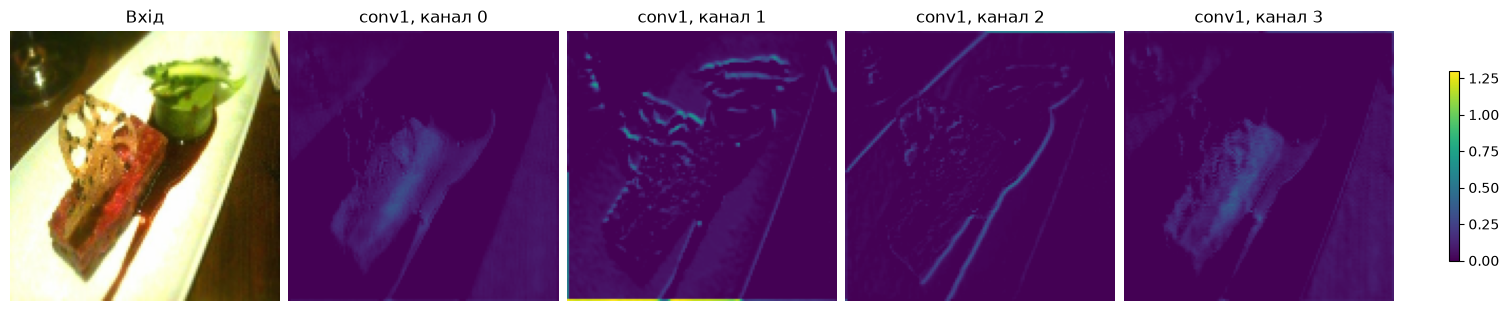

In [11]:
fig,axes=plt.subplots(1,5,figsize=(15,3),layout='constrained')
axes[0].imshow(example_batch[0].numpy().astype('uint8')); axes[0].set_title('Вхід'); axes[0].axis('off')
vmax=float(feature_maps[0,:,:,:4].max())
for c in range(4):
    im=axes[c+1].imshow(feature_maps[0,:,:,c],vmin=0,vmax=vmax,cmap='viridis')
    axes[c+1].set_title(f'conv1, канал {c}'); axes[c+1].axis('off')
fig.colorbar(im,ax=list(axes[1:]),shrink=.7)
fig.savefig(RESULTS / 'feature_maps.png',dpi=150)
plt.show(); plt.close(fig)

### 34. Збереження порядку класів і передобробки

### 8 Збереження і незалежне відновлення
Вхід моделі — RGB float32 у шкалі 0–255; resize bilinear до 128×128.
Ділити на 255 до predict не потрібно, бо Rescaling входить у модель.
Три validation-приклади та очікувані оцінки використовуємо для перевірки відновлення без fit.

In [12]:
metadata = {'student':'Михайло Вахнюк','variant':NUMBER,'class_names':CLASS_NAMES,
            'image_size':list(IMAGE_SIZE),'color_mode':'rgb','interpolation':'bilinear',
            'input_range':[0,255],'input_dtype':'float32','rescaling_inside_model':True,
            'label_mode':'int','loss':'SparseCategoricalCrossentropy(from_logits=False)',
            'seed':SEED,'selected_model':selected_name,'parameters':selected_model.count_params()}
(ROOT / 'metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')

### 35. Перевірка відновлення на трьох validation-зображеннях

In [12]:
probe=next(iter(val_ds))[0][:3].numpy()
expected=selected_model.predict(probe,verbose=0)
np.savez(RESULTS / 'reload_probe.npz',images=probe,probabilities=expected)
restored=keras.models.load_model(ROOT / 'food_cnn.keras')
np.testing.assert_allclose(restored.predict(probe,verbose=0),expected,rtol=1e-5,atol=1e-6)
print('Відновлена модель повторює прогнози трьох validation-зображень.')

Відновлена модель повторює прогнози трьох validation-зображень.


### 36. Прогноз на власному фото тартару

### 9 Власне фото обраного класу
Використовуємо надане користувачем фото тартару: own_photo/beef_tartare.jpg.
Передобробка: RGB, 128×128, bilinear, float32, додавання batch-виміру.
Rescaling уже входить у модель; повторно на 255 не ділимо. Фото не бере участі у fit або test.

,class,softmax
0,beef_tartare,0.449496
1,eggs_benedict,0.510428
2,miso_soup,0.040076


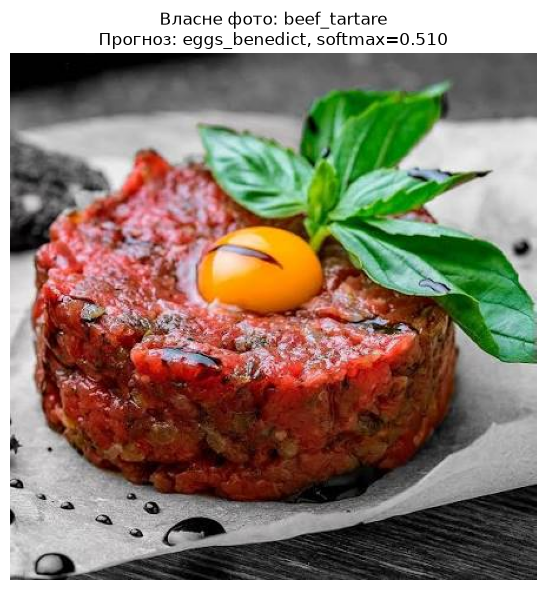

321

In [2]:
photo_candidates = [p for name in CLASS_NAMES for ext in ('jpg', 'jpeg', 'png')
                    if (p := ROOT / 'own_photo' / f'{name}.{ext}').is_file()]
if photo_candidates:
    OWN_PHOTO = photo_candidates[0]
    known_class = OWN_PHOTO.stem
    own_image = keras.utils.load_img(OWN_PHOTO, target_size=IMAGE_SIZE,
                                     color_mode='rgb', interpolation='bilinear')
    own_array = keras.utils.img_to_array(own_image)[None, ...]
    own_scores = restored.predict(own_array, verbose=0)[0]
    own_label = int(own_scores.argmax())
    own_result = {'status': 'completed', 'photo': OWN_PHOTO.relative_to(ROOT).as_posix(),
                  'known_class': known_class, 'predicted_class': CLASS_NAMES[own_label],
                  'max_softmax': float(own_scores[own_label]),
                  'probabilities': dict(zip(CLASS_NAMES, map(float, own_scores)))}
    display(pd.DataFrame({'class': CLASS_NAMES, 'softmax': own_scores}))
    fig, ax = plt.subplots(figsize=(6, 6))
    with Image.open(OWN_PHOTO) as im:
        ax.imshow(im.convert('RGB'))
    ax.set_title(f'Власне фото: {known_class}\nПрогноз: {CLASS_NAMES[own_label]}, softmax={own_scores[own_label]:.3f}')
    ax.axis('off')
    save_show(fig, 'own_photo_prediction.png')
else:
    own_result = {'status': 'pending_user_photo', 'accepted_classes': CLASS_NAMES,
                  'reason': 'Власне фото одного з класів варіанта 5 ще не надано; baklava до них не належить'}
    print(own_result['reason'])
    print('Додайте own_photo/miso_soup.jpg, eggs_benedict.jpg або beef_tartare.jpg.')
(RESULTS / 'own_photo_prediction.json').write_text(
    json.dumps(own_result, ensure_ascii=False, indent=2), encoding='utf-8')

**Результат прогнозування фото.** На наданому фото справжній клас — beef_tartare. Модель обрала eggs_benedict з оцінкою softmax 51.04%; оцінка правильного класу — 44.95%, miso_soup — 4.01%. Прогноз помилковий. Argmax обрав найбільшу з трьох оцінок; різниця між двома провідними класами невелика. Жовток і зелень видимі в кадрі та можуть ускладнювати розрізнення страв, але без окремого дослідження не можна стверджувати, що саме вони спричинили рішення. Модель не перенавчали й фото не додавали до train або test.

### 37. Висновки за фактичними результатами

### Аналіз отриманих графіків і помилок

Базова CNN виконала 22 епохи, найкраща — 17-та: validation loss 0.6158, accuracy 76.67%. Мережа з Dropout 0.3 виконала 30 епох і досягла найменшого validation loss 0.5745 на 30-й, accuracy 78.89%. Різниця loss становить −0.0413. На цьому поділі гіпотеза покращення підтвердилася, але модель із Dropout навчалася довше: приблизно 628 с проти 465 с. Кількість параметрів обох моделей — 23 779.

На кривих train і validation загалом зменшуються, однак validation має помітні коливання. У базової мережі після найкращої епохи train loss зменшується, а validation не перевершує мінімум; це аргумент для відновлення checkpoint. У мережі з Dropout мінімум досягнуто на останній дозволеній епосі, тому 30 епох не доводять повної збіжності. Вища validation accuracy за train accuracy узгоджується з різними режимами Dropout та можливим шумом train-міток; вона сама не доводить недонавчання.

Матриця помилок показує 113 правильних tartare, 213 eggs_benedict і 207 miso_soup із 250 кожного класу. Найчастіша плутанина — beef_tartare → eggs_benedict: 123 випадки. Recall тартару лише 113/250 = 45.2%, яєць Бенедикт — 85.2%, місо-супу — 82.8%. Отже, загальна test accuracy 71.07% приховує значно слабше розпізнавання тартару; macro-F1=0.7048 враховує всі класи з однаковою вагою.

На галереї шести найвпевненіших помилок: (1) темне фото тартару помилково віднесене до супу з оцінкою 0.981; (2) тартар із жовтком і симетричним гарніром — до яєць Бенедикт, 0.953; (3) тартар із картоплею та виразним візерунком тарілки — до яєць, 0.950; (4) яйця на темному тлі — до супу, 0.883; (5) яйця з великою часткою фруктового гарніру — до супу, 0.854; (6) тартар, жовток, зелень і картопля на одній тарілці — до яєць, 0.854. Це спостережувані особливості кадрів і можливі причини складності, а не доведені пояснення рішення мережі. Незвичне оформлення й ракурс можуть ускладнювати класифікацію; незгода моделі з міткою не доводить її хибність. Фото не видаляли з test.

На картах першого Conv канал 1 підкреслює локальні текстури, канал 2 — виразні краї тарілки й предметів; у каналах 0 і 3 відгуки слабші та більш плавні. Це активації конкретного входу після ReLU, а не самі ядра. Шкала кольору спільна для чотирьох карт. Вона показує локальні відгуки, але не доводить, що саме ці ділянки спричинили фінальну класифікацію.

Під час огляду train-прикладів фото beef_tartare/1009672.jpg значною мірою закрите зеленню, а eggs_benedict/1008725.jpg має темне освітлення й нетипову подачу. Явних близьких копій серед показаних 12 фото не помічено; це не перевірка всього набору. SHA-256 підтвердив лише відсутність точних дублікатів.

**Прогноз на наданому фото.** На наданому фото справжній клас — beef_tartare. Модель обрала eggs_benedict з оцінкою softmax 51.04%; оцінка правильного класу — 44.95%, miso_soup — 4.01%. Прогноз помилковий. Argmax обрав найбільшу з трьох оцінок; різниця між двома провідними класами невелика. Жовток і зелень видимі в кадрі та можуть ускладнювати розрізнення страв, але без окремого дослідження не можна стверджувати, що саме вони спричинили рішення. Модель не перенавчали й фото не додавали до train або test.

In [3]:
best=next(r for r in rows if r['model']==selected_name)
text=(f'### Висновки\n\n'
      f'Побудовано власну CNN для класів {", ".join(CLASS_NAMES)} з 23779 параметрами. '
      f'Використано 1800 train, 450 validation та 750 незалежних офіційних test-зображень; '
      f'перевірено читабельність і відсутність точних дублікатів між частинами. '
      f'Ручна згортка підтверджена кодом: після bias=1 та ReLU отримано [[1,0],[0,1]]. '
      f'Єдиною зміною був Dropout 0.3 після GAP; зміна validation loss становила {delta:+.4f}, '
      f'тому гіпотеза {"підтвердилася" if delta<0 else "не підтвердилася"} на цьому поділі. '
      f'За мінімальним validation loss обрано {selected_name}, найкраща епоха {best["best_epoch"]}. '
      f'На test accuracy={summary["test_accuracy"]:.4f}, macro-F1={summary["macro_f1"]:.4f}; '
      f'Dummy accuracy={summary["dummy_accuracy"]:.4f}. '
      f'Отримано {summary["error_count"]} помилок із 750; softmax не гарантує правильності окремого прогнозу. '
      f'Карти першого Conv показують залежні від входу просторові відгуки після ReLU; '
      f'збереження та відновлення перевірено на трьох validation-прикладах. '
      f'Обмеження: один seed, невелика підмножина, шум міток, спотворення пропорцій resize '
      f'та відсутність класу невідомих об’єктів. Наступний обґрунтований крок — '
      f'перевірити аугментацію як окремий експеримент на кількох seed, зберігаючи новий незалежний test для подальшої фінальної оцінки.')
if own_result['status'] != 'completed':
    text += ' Обов’язковий прогноз власного фото обраного класу ще очікує відповідного фото користувача.'
display(Markdown(text))
(RESULTS / 'conclusion.md').write_text(text+'\n',encoding='utf-8')

### Висновки

Побудовано власну CNN для класів beef_tartare, eggs_benedict, miso_soup з 23779 параметрами. Використано 1800 train, 450 validation та 750 незалежних офіційних test-зображень; перевірено читабельність і відсутність точних дублікатів між частинами. Ручна згортка підтверджена кодом: після bias=1 та ReLU отримано [[1,0],[0,1]]. Єдиною зміною був Dropout 0.3 після GAP; зміна validation loss становила -0.0413, тому гіпотеза підтвердилася на цьому поділі. За мінімальним validation loss обрано dropout03, найкраща епоха 30. На test accuracy=0.7107, macro-F1=0.7048; Dummy accuracy=0.3333. Отримано 217 помилок із 750; softmax не гарантує правильності окремого прогнозу. Карти першого Conv показують залежні від входу просторові відгуки після ReLU; збереження та відновлення перевірено на трьох validation-прикладах. Обмеження: один seed, невелика підмножина, шум міток, спотворення пропорцій resize та відсутність класу невідомих об’єктів. Наступний обґрунтований крок — перевірити аугментацію як окремий експеримент на кількох seed, зберігаючи новий незалежний test для подальшої фінальної оцінки.

1111

### 10 Питання для самоперевірки
1. Одне значення згортки — сума поелементних добутків локального вікна й ядра плюс bias.
2. RGB-ядро 3×3 має 3·3·3=27 ваг, бо охоплює три вхідні канали.
3. Stride визначає крок вікна, padding — доповнення країв; обидва впливають на форму виходу.
4. GAP усереднює кожну карту, Flatten розгортає всі її значення в один вектор.
5. Softmax задає три взаємовиключні виходи; sparse loss приймає цілі індекси класів.
6. Validation слугує вибору моделі; test — фінальній незалежній оцінці після вибору.
7. Dropout може допомогти проти перенавчання, але також послабити корисні ознаки або сповільнити навчання.
8. Macro-F1 однаково зважує якість класів; матриця помилок показує напрямки плутанини.
9. Ядро — навчувані ваги, карта активацій — залежний від входу результат застосування фільтра.
10. Softmax нормує оцінки лише відомих класів і завжди обирає один із них, навіть для невідомого об'єкта.